# Single-location state and measurement optimization

$M=1$, $K\in\{3,4,5\}$, $N\in\{2,4,6,8,10\}$, with 30 instances per field family and $K$. Budgets share the same field instances. Field priors are uniform.

The state is $|\psi\rangle=\sum_{w=0}^N\sqrt{p_w}|D_N^w\rangle$. Product, GHZ and equal-sector weights are respectively $\binom Nw/2^N$, equal endpoint weights, and $1/(N+1)$. 

Optimized weights are numerical SLSQP solutions to the optimal-POVM objective, without a global optimality certificate. PGM is evaluated on the same optimized state.

## Environment

Install missing dependencies in the active kernel. Restart the kernel after installation if already loaded packages were upgraded.

In [ ]:
from pathlib import Path
import sys
import importlib.util
import subprocess

ROOT = Path.cwd().resolve()
if not (ROOT / "single_location").is_dir():
    ROOT = ROOT / "problem-3-single-location"
if not (ROOT / "single_location").is_dir():
    raise FileNotFoundError("Open from the project folder or repository root")

required = ("cvxpy", "numpy", "pandas", "scipy", "matplotlib")
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    print("Installing missing dependencies into the active kernel:", ", ".join(missing))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-r", str(ROOT / "requirements.txt")
    ])
    importlib.invalidate_caches()
    raise RuntimeError("Dependencies installed. Restart the kernel, then run all cells.")
print("Python environment:", sys.executable)


In [ ]:
from IPython.display import display
import pandas as pd

sys.path.insert(0, str(ROOT))
KS = (3, 4, 5)
NS = (2, 4, 6, 8, 10)
RUN_ANALYSIS = False


## Saved results

Reporting uses `results/measurements.csv` and the corresponding saved weights. No state optimization or measurement evaluation is performed when `RUN_ANALYSIS=False`. All results use $M=1$; the dataset contains no other location counts.


In [ ]:
if RUN_ANALYSIS:
    from single_location.analysis import run_analysis
    status = display({"text/plain": "Starting analysis"}, raw=True, display_id=True)

    def show_progress(message):
        status.update({"text/plain": message}, raw=True)

    measurements = run_analysis(ROOT, ks=KS, ns=NS, progress=show_progress)
else:
    measurements = pd.read_csv(ROOT / "results/measurements.csv")
    print(f"Loaded {len(measurements)} saved state evaluations; M=1, K={KS}, N={NS}.")


## Results

Each figure has three panels: Gaussian, sinusoidal and quadratic. Performance curves average equally over $K=3,4,5$ (30 instances per $K$, 90 in total per curve point). Figure 1 compares four states with optimal POVMs. Figure 2 shows the paired excess error from PGM. Curves show means without shaded bands; figure-summary tables include stratified 95% confidence intervals for the equal-weight mean. Separate tables retain results for each $K$.

Figure 3 compares $p_w$ with $p_{N-w}$ for every saved optimized state across all three $K$ values, with colors indicating sensor budget. Each point is one pair of distinct reflected sectors from one instance. Points on the diagonal satisfy reflection symmetry. The central sector is omitted because it equals its own reflection. Permutation symmetry does not imply reflection symmetry.

The symmetry table reports $\max_w|p_w-p_{N-w}|$ per instance, summarized by field family, $K$ and $N$. The fraction within $10^{-5}$ is a numerical diagnostic, not a symmetry constraint imposed on the optimizer.


Overall Errors


state                          equal                  ghz            optimized              product
family     m n                                                                                     
gaussian   1 2   0.597750 ± 0.014331  0.576815 ± 0.015257  0.576410 ± 0.015362  0.613701 ± 0.013032
             4   0.523131 ± 0.019764  0.526759 ± 0.014738  0.491576 ± 0.019538  0.570868 ± 0.016681
             6   0.467474 ± 0.023510  0.522013 ± 0.014001  0.433611 ± 0.023331  0.541597 ± 0.018950
             8   0.423626 ± 0.026280  0.520223 ± 0.013780  0.390086 ± 0.025897  0.519162 ± 0.020590
             10  0.388600 ± 0.028237  0.519835 ± 0.013658  0.355180 ± 0.027992  0.500957 ± 0.021865
quadratic  1 2   0.616585 ± 0.010301  0.594290 ± 0.011632  0.594276 ± 0.011636  0.631409 ± 0.009207
             4   0.543083 ± 0.015465  0.518986 ± 0.013322  0.505859 ± 0.015786  0.591389 ± 0.012329
             6   0.482122 ± 0.019355  0.503129 ± 0.011757  0.441884 ± 0.019338  0.562418 ± 0.014488
             8   0.429783 ± 0.022429  0.505401 ± 0.011199  0.387483 ± 0.022293  0.539114 ± 0.016156
             10  0.384726 ± 0.024698  0.509645 ± 0.010148  0.342313 ± 0.024148  0.519421 ± 0.017511
sinusoidal 1 2   0.477696 ± 0.017057  0.501869 ± 0.009980  0.466269 ± 0.015520  0.497107 ± 0.016898
             4   0.353640 ± 0.023190  0.498295 ± 0.009066  0.333410 ± 0.021857  0.419799 ± 0.021139
             6   0.276193 ± 0.024457  0.507522 ± 0.010622  0.254468 ± 0.023068  0.372365 ± 0.022909
             8   0.223937 ± 0.024441  0.494386 ± 0.008464  0.201003 ± 0.023506  0.338902 ± 0.023759
             10  0.184525 ± 0.024578  0.494776 ± 0.008263  0.162434 ± 0.023260  0.313485 ± 0.024196

Overall Degradation


state                          equal                  ghz            optimized              product
family     m n                                                                                     
gaussian   1 2   0.010932 ± 0.001147  0.016094 ± 0.001849  0.015506 ± 0.001818  0.009967 ± 0.001000
             4   0.008229 ± 0.001076  0.013110 ± 0.002059  0.010590 ± 0.001821  0.008443 ± 0.000914
             6   0.006447 ± 0.001009  0.013027 ± 0.002080  0.007627 ± 0.001517  0.007447 ± 0.000891
             8   0.005279 ± 0.000934  0.013661 ± 0.002099  0.005975 ± 0.001223  0.006729 ± 0.000873
             10  0.004440 ± 0.000865  0.013412 ± 0.002238  0.004681 ± 0.001133  0.006185 ± 0.000858
quadratic  1 2   0.014154 ± 0.000933  0.020678 ± 0.001592  0.020596 ± 0.001578  0.012461 ± 0.000821
             4   0.011950 ± 0.000843  0.016688 ± 0.001919  0.015144 ± 0.001693  0.011550 ± 0.000683
             6   0.008861 ± 0.000926  0.010677 ± 0.002077  0.010176 ± 0.001653  0.010446 ± 0.000675
             8   0.006981 ± 0.000956  0.013134 ± 0.002196  0.008715 ± 0.001616  0.009463 ± 0.000697
             10  0.005922 ± 0.000955  0.013866 ± 0.002127  0.007098 ± 0.001453  0.008642 ± 0.000720
sinusoidal 1 2   0.010682 ± 0.001071  0.013853 ± 0.002186  0.012924 ± 0.001869  0.010655 ± 0.000903
             4   0.005321 ± 0.000929  0.011811 ± 0.002157  0.007013 ± 0.001503  0.006090 ± 0.000818
             6   0.003300 ± 0.000826  0.013261 ± 0.002010  0.003782 ± 0.001034  0.004524 ± 0.000767
             8   0.002197 ± 0.000704  0.010865 ± 0.002024  0.002217 ± 0.000798  0.003649 ± 0.000733
             10  0.001520 ± 0.000588  0.012045 ± 0.001940  0.001548 ± 0.000676  0.003078 ± 0.000702

Errors


state                            equal                  ghz            optimized              product
family     k m n                                                                                     
gaussian   3 1 2   0.496443 ± 0.032655  0.469770 ± 0.035360  0.469594 ± 0.035453  0.515896 ± 0.029606
               4   0.412861 ± 0.043074  0.411936 ± 0.035526  0.374355 ± 0.043074  0.467122 ± 0.036965
               6   0.357349 ± 0.048836  0.409588 ± 0.034866  0.319720 ± 0.049068  0.435401 ± 0.041061
               8   0.316773 ± 0.052686  0.408692 ± 0.033477  0.281021 ± 0.052122  0.412044 ± 0.043775
               10  0.286050 ± 0.055058  0.417449 ± 0.034703  0.249110 ± 0.055158  0.393683 ± 0.045752
           4 1 2   0.609281 ± 0.022554  0.588954 ± 0.023402  0.588371 ± 0.023720  0.625155 ± 0.020594
               4   0.530171 ± 0.033086  0.533050 ± 0.020916  0.497952 ± 0.032339  0.580488 ± 0.027325
               6   0.468433 ± 0.040729  0.530181 ± 0.018652  0.433400 ± 0.039972  0.549147 ± 0.031810
               8   0.420563 ± 0.045744  0.533120 ± 0.022061  0.386873 ± 0.044766  0.524776 ± 0.035103
               10  0.383245 ± 0.048849  0.527092 ± 0.019832  0.351979 ± 0.047966  0.504865 ± 0.037639
           5 1 2   0.687525 ± 0.019238  0.671722 ± 0.020109  0.671266 ± 0.020345  0.700052 ± 0.017560
               4   0.626362 ± 0.027530  0.635293 ± 0.018687  0.602422 ± 0.026843  0.664994 ± 0.022938
               6   0.576639 ± 0.034816  0.626270 ± 0.016710  0.547713 ± 0.034185  0.640242 ± 0.026682
               8   0.533542 ± 0.041299  0.618858 ± 0.013422  0.502362 ± 0.040778  0.620667 ± 0.029664
               10  0.496505 ± 0.046650  0.614965 ± 0.012257  0.464450 ± 0.046022  0.604323 ± 0.032177
quadratic  3 1 2   0.524504 ± 0.025213  0.498099 ± 0.028714  0.498099 ± 0.028714  0.541867 ± 0.022471
               4   0.440159 ± 0.037810  0.405899 ± 0.034899  0.393715 ± 0.039827  0.496076 ± 0.029988
               6   0.374042 ± 0.046684  0.388543 ± 0.032699  0.325673 ± 0.047689  0.463689 ± 0.035041
               8   0.322302 ± 0.052937  0.396561 ± 0.031795  0.274522 ± 0.053143  0.438295 ± 0.038822
               10  0.282424 ± 0.056683  0.409232 ± 0.028086  0.236063 ± 0.055553  0.417383 ± 0.041797
           4 1 2   0.632794 ± 0.016023  0.611249 ± 0.018059  0.611249 ± 0.018059  0.647038 ± 0.014337
               4   0.561341 ± 0.024149  0.537547 ± 0.018876  0.524912 ± 0.023488  0.608281 ± 0.019305
               6   0.500276 ± 0.030773  0.516883 ± 0.013475  0.459249 ± 0.029592  0.579889 ± 0.022869
               8   0.445926 ± 0.036584  0.514593 ± 0.010732  0.401697 ± 0.035630  0.556785 ± 0.025723
               10  0.397740 ± 0.041422  0.515550 ± 0.011659  0.353018 ± 0.040058  0.537054 ± 0.028117
           5 1 2   0.692459 ± 0.010290  0.673522 ± 0.011006  0.673479 ± 0.011043  0.705321 ± 0.009342
               4   0.627747 ± 0.015424  0.613513 ± 0.008970  0.598952 ± 0.014104  0.669809 ± 0.012613
               6   0.572048 ± 0.020082  0.603962 ± 0.004813  0.540728 ± 0.019137  0.643677 ± 0.015053
               8   0.521121 ± 0.024668  0.605048 ± 0.004904  0.486231 ± 0.024388  0.622261 ± 0.017078
               10  0.474013 ± 0.029012  0.604153 ± 0.005054  0.437858 ± 0.028730  0.603824 ± 0.018831
sinusoidal 3 1 2   0.369331 ± 0.041731  0.384169 ± 0.027137  0.351250 ± 0.038479  0.392537 ± 0.041020
               4   0.251199 ± 0.052666  0.375976 ± 0.025204  0.223822 ± 0.050458  0.317797 ± 0.048772
               6   0.187646 ± 0.051944  0.396826 ± 0.029177  0.159918 ± 0.049191  0.275105 ± 0.051367
               8   0.146492 ± 0.050129  0.369954 ± 0.024064  0.116306 ± 0.048365  0.246250 ± 0.052221
               10  0.116777 ± 0.048939  0.367455 ± 0.022194  0.089832 ± 0.045783  0.224923 ± 0.052369
           4 1 2   0.476671 ± 0.024629  0.510901 ± 0.009367  0.467563 ± 0.021676  0.496031 ± 0.024934
               4   0.336472 ± 0.038420  0.511659 ± 0.008686  0.318763 ± 0.035489  0.408716 ± 0.034262
               6   0.2

Degradation


state                            equal                  ghz            optimized              product
family     k m n                                                                                     
gaussian   3 1 2   0.007795 ± 0.001818  0.012352 ± 0.003277  0.011876 ± 0.003179  0.007053 ± 0.001503
               4   0.005003 ± 0.001698  0.012502 ± 0.003440  0.007331 ± 0.003327  0.005553 ± 0.001414
               6   0.002972 ± 0.001252  0.012694 ± 0.003632  0.002663 ± 0.001547  0.004542 ± 0.001321
               8   0.001774 ± 0.000916  0.011236 ± 0.003256  0.001407 ± 0.001122  0.003811 ± 0.001215
               10  0.001171 ± 0.000762  0.014004 ± 0.003713  0.001116 ± 0.001112  0.003258 ± 0.001114
           4 1 2   0.012287 ± 0.001969  0.018287 ± 0.003068  0.017486 ± 0.003122  0.011160 ± 0.001711
               4   0.009302 ± 0.002098  0.013782 ± 0.004210  0.011771 ± 0.003511  0.009429 ± 0.001705
               6   0.007111 ± 0.002101  0.013846 ± 0.004059  0.008666 ± 0.003300  0.008293 ± 0.001742
               8   0.005558 ± 0.002002  0.015243 ± 0.004234  0.006502 ± 0.002729  0.007452 ± 0.001756
               10  0.004447 ± 0.001765  0.014067 ± 0.004119  0.004434 ± 0.002068  0.006799 ± 0.001756
           5 1 2   0.012715 ± 0.002310  0.017643 ± 0.003522  0.017157 ± 0.003411  0.011689 ± 0.002082
               4   0.010381 ± 0.001935  0.013044 ± 0.003282  0.012669 ± 0.002863  0.010347 ± 0.001746
               6   0.009259 ± 0.001919  0.012542 ± 0.003396  0.011551 ± 0.002915  0.009506 ± 0.001667
               8   0.008506 ± 0.001845  0.014503 ± 0.003664  0.010016 ± 0.002328  0.008926 ± 0.001641
               10  0.007703 ± 0.001838  0.012165 ± 0.004117  0.008493 ± 0.002574  0.008500 ± 0.001633
quadratic  3 1 2   0.010283 ± 0.001608  0.016110 ± 0.003117  0.016110 ± 0.003117  0.008989 ± 0.001352
               4   0.007743 ± 0.001523  0.014064 ± 0.003367  0.011297 ± 0.003401  0.007816 ± 0.001131
               6   0.005068 ± 0.001665  0.010938 ± 0.003542  0.006189 ± 0.003266  0.006732 ± 0.001134
               8   0.003565 ± 0.001691  0.015791 ± 0.004019  0.004222 ± 0.002823  0.005859 ± 0.001176
               10  0.002817 ± 0.001653  0.014647 ± 0.003782  0.003689 ± 0.003025  0.005171 ± 0.001218
           4 1 2   0.015147 ± 0.001767  0.022121 ± 0.002903  0.022121 ± 0.002903  0.013276 ± 0.001565
               4   0.013144 ± 0.001672  0.018608 ± 0.003751  0.016800 ± 0.003288  0.012452 ± 0.001340
               6   0.009864 ± 0.001958  0.012287 ± 0.003879  0.011674 ± 0.003379  0.011344 ± 0.001379
               8   0.007589 ± 0.001996  0.013037 ± 0.003977  0.009744 ± 0.003211  0.010319 ± 0.001468
               10  0.006127 ± 0.001933  0.013126 ± 0.003729  0.007509 ± 0.002682  0.009441 ± 0.001545
           5 1 2   0.017031 ± 0.001609  0.023803 ± 0.002444  0.023558 ± 0.002354  0.015118 ± 0.001465
               4   0.014962 ± 0.001284  0.017391 ± 0.003110  0.017335 ± 0.002198  0.014383 ± 0.001167
               6   0.011651 ± 0.001237  0.008805 ± 0.003676  0.012664 ± 0.001960  0.013262 ± 0.001071
               8   0.009789 ± 0.001356  0.010574 ± 0.003740  0.012177 ± 0.002568  0.012210 ± 0.001036
               10  0.008822 ± 0.001485  0.013826 ± 0.003860  0.010097 ± 0.001924  0.011315 ± 0.001025
sinusoidal 3 1 2   0.006373 ± 0.002108  0.014000 ± 0.003787  0.010760 ± 0.004191  0.006077 ± 0.001734
               4   0.002327 ± 0.001477  0.014158 ± 0.003770  0.003146 ± 0.002895  0.003286 ± 0.001422
               6   0.001119 ± 0.001011  0.013714 ± 0.003595  0.001060 ± 0.001267  0.002210 ± 0.001204
               8   0.000654 ± 0.000713  0.011051 ± 0.003272  0.000550 ± 0.000830  0.001639 ± 0.001053
               10  0.000455 ± 0.000623  0.012643 ± 0.003846  0.000509 ± 0.000960  0.001294 ± 0.000937
           4 1 2   0.010531 ± 0.001888  0.012865 ± 0.004052  0.011874 ± 0.002918  0.010764 ± 0.001627
               4   0.004923 ± 0.001775  0.011141 ± 0.004102  0.006779 ± 0.002757  0.005682 ± 0.001534
               6   0.0

Symmetry


,family,k,m,n,count,mean,ci95,lower95,upper95,maximum_asymmetry,fraction_within_tolerance,tolerance
0,gaussian,3,1,2,30,5.695184e-07,7.915275e-07,-2.220091e-07,1.361046e-06,9.345261e-06,1.000000,0.00001
1,gaussian,3,1,4,30,7.867399e-06,5.915281e-06,1.952118e-06,1.378268e-05,7.084006e-05,0.800000,0.00001
2,gaussian,3,1,6,30,1.068351e-05,6.140024e-06,4.543483e-06,1.682353e-05,6.698920e-05,0.666667,0.00001
3,gaussian,3,1,8,30,4.488485e-05,4.740641e-05,-2.521560e-06,9.229125e-05,6.490934e-04,0.600000,0.00001
4,gaussian,3,1,10,30,2.506492e-05,1.843684e-05,6.628075e-06,4.350176e-05,1.909940e-04,0.600000,0.00001
5,gaussian,4,1,2,30,2.698988e-06,3.463095e-06,-7.641068e-07,6.162083e-06,4.854931e-05,0.933333,0.00001
6,gaussian,4,1,4,30,7.805950e-06,4.512085e-06,3.293865e-06,1.231804e-05,4.550863e-05,0.766667,0.00001
7,gaussian,4,1,6,30,8.465565e-04,1.692929e-03,-8.463723e-04,2.539485e-03,2.485063e-02,0.533333,0.00001
8,gaussian,4,1,8,30,4.013268e-05,3.407899e-05,6.053694e-06,7.421167e-05,4.833748e-04,0.333333,0.00001
9,gaussian,4,1,10,30,4.171353e-03,7.402849e-03,-3.231496e-03,1.157420e-02,1.088711e-01,0.233333,0.00001


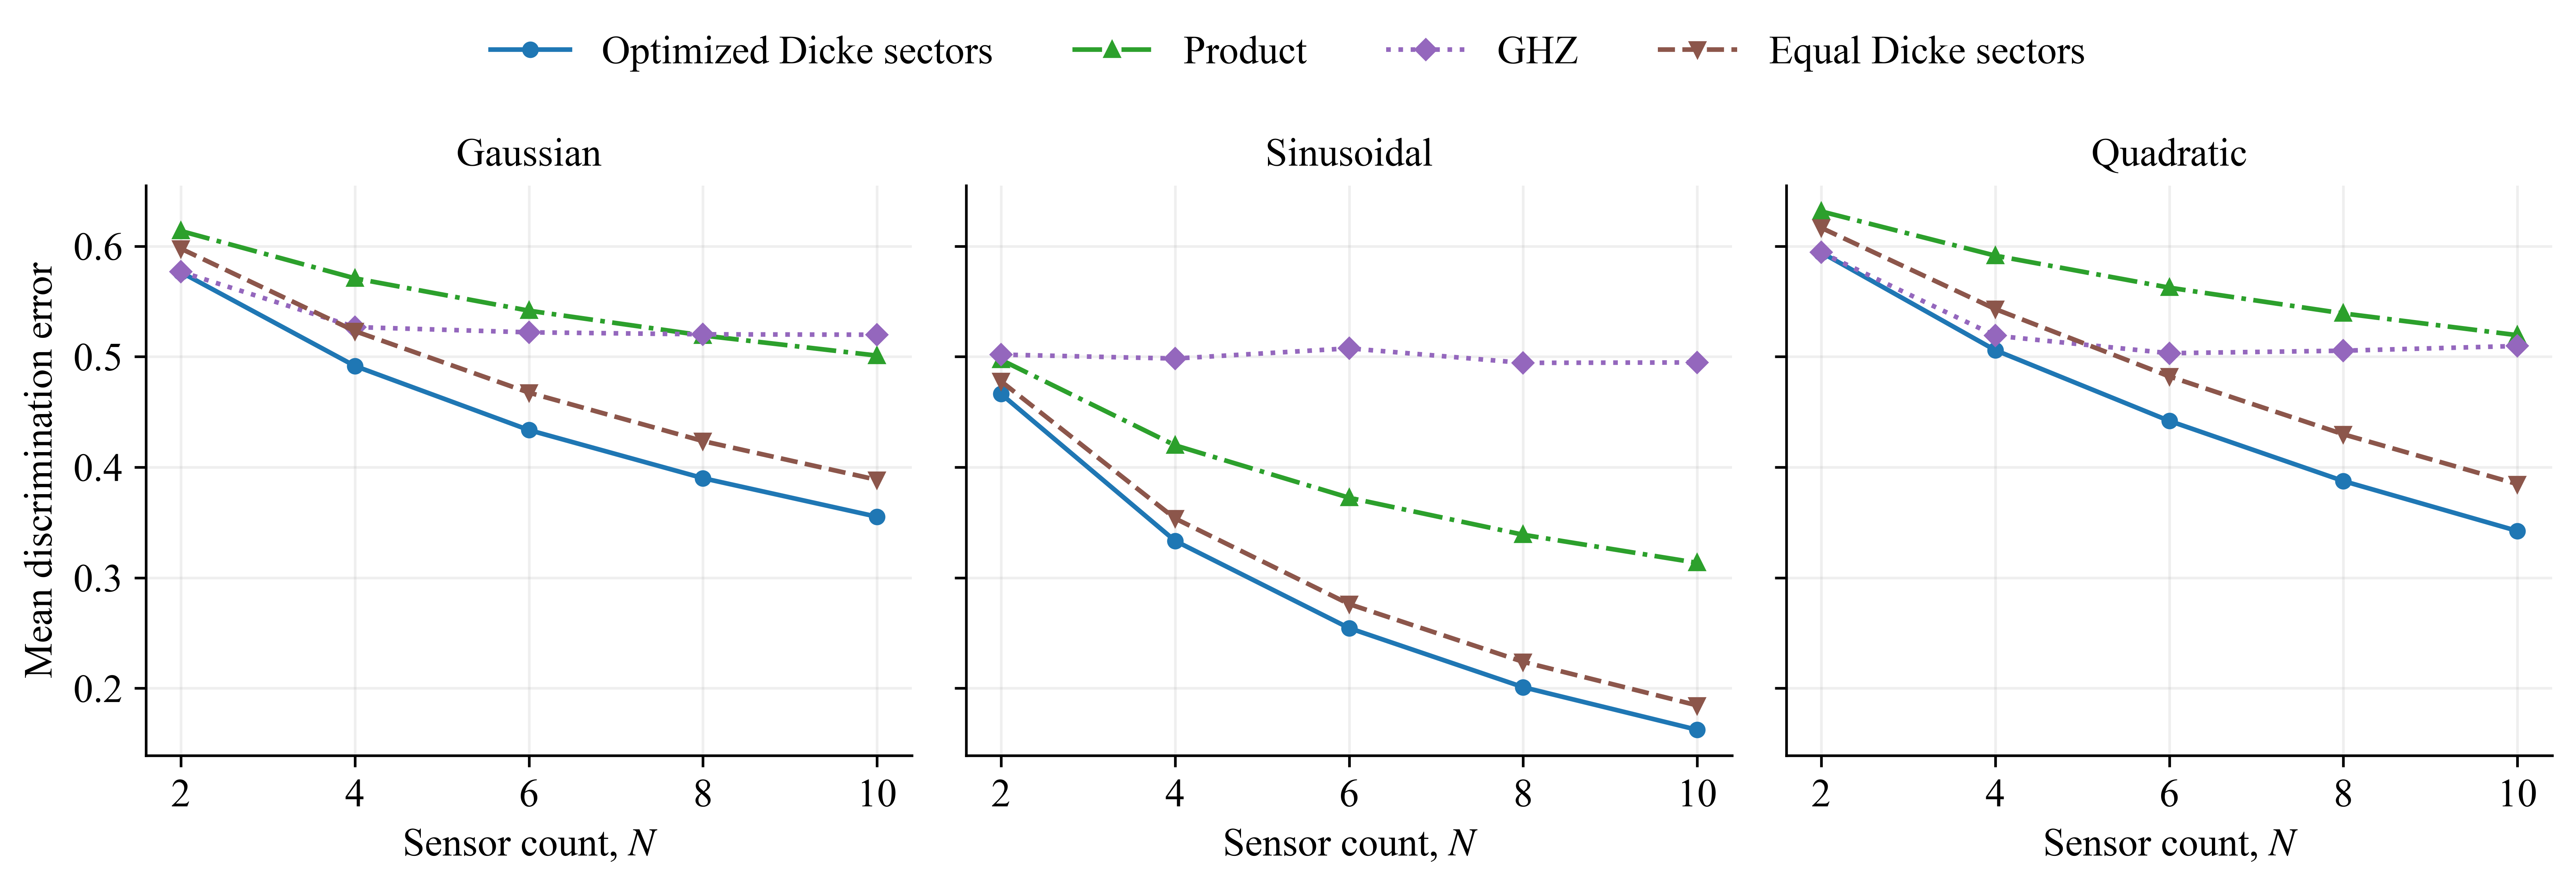

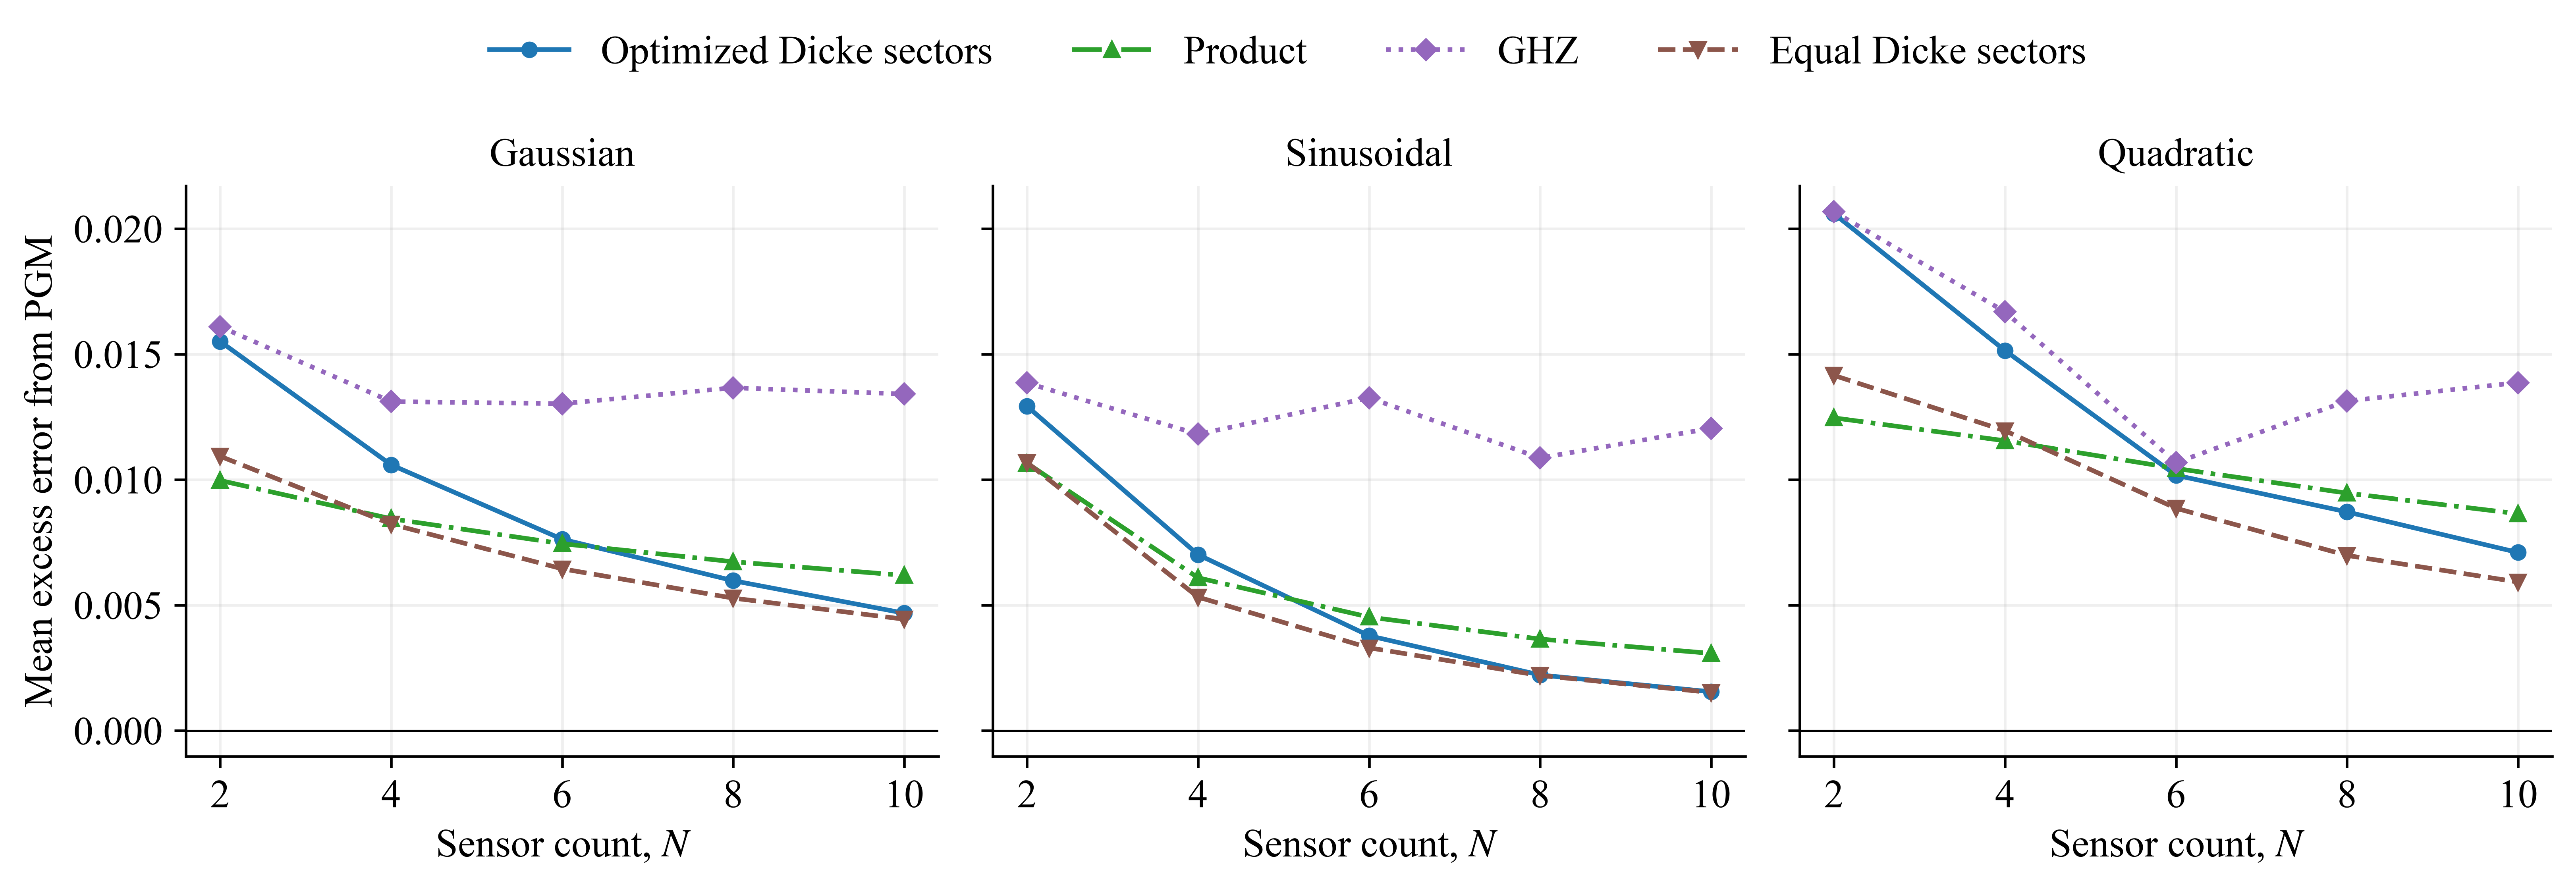

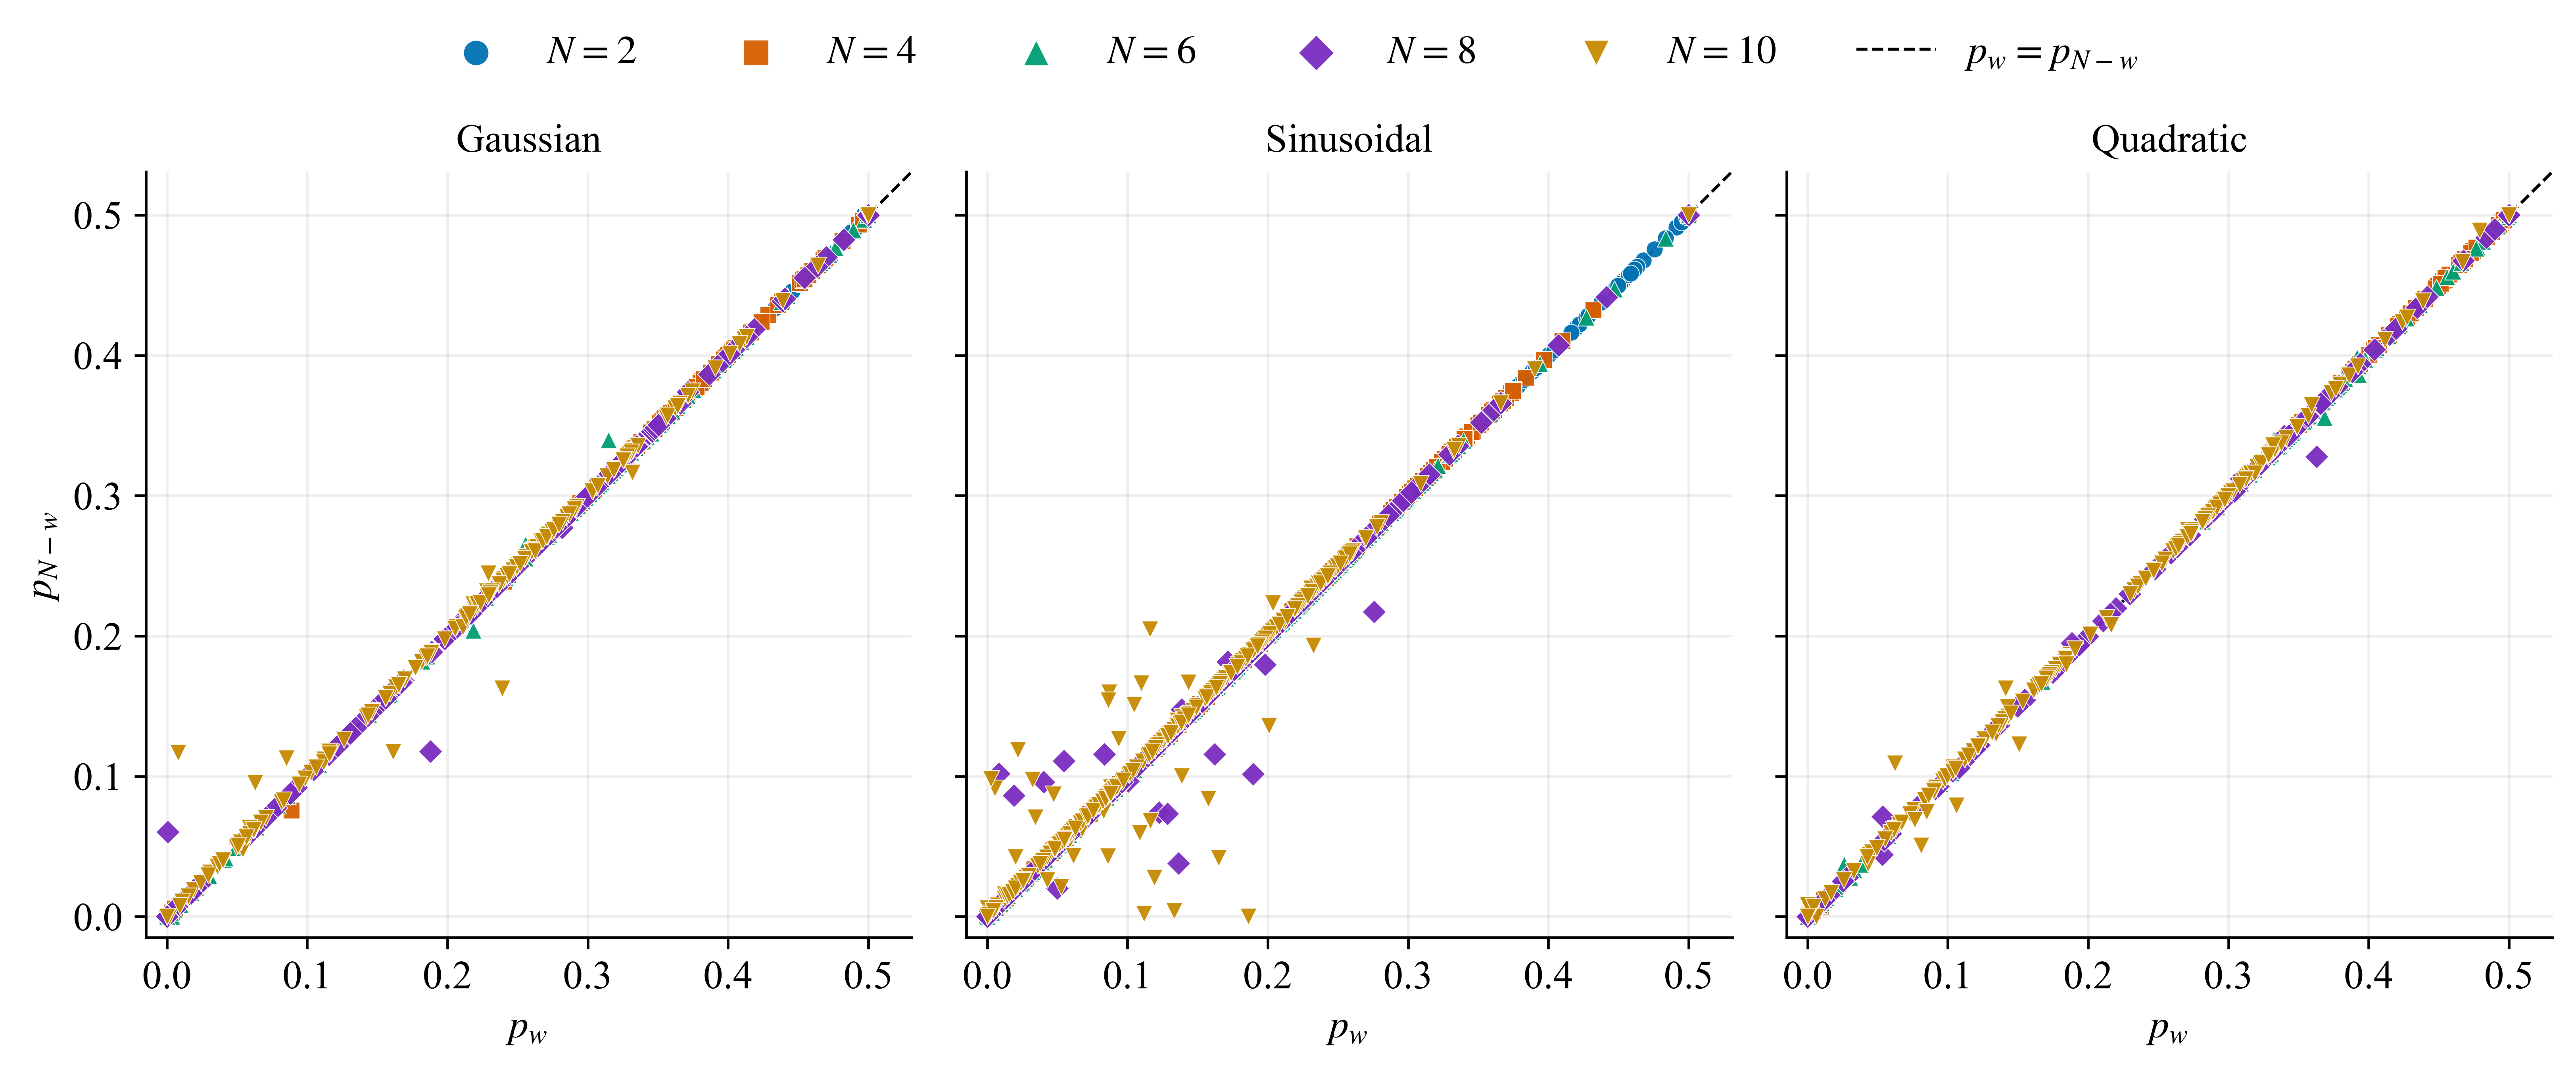

In [ ]:
import importlib
import matplotlib.pyplot as plt
import single_location.reporting as reporting

reporting = importlib.reload(reporting)
results = reporting.make_results(measurements, ROOT)
for name in ("overall_errors", "overall_degradation", "errors", "degradation", "symmetry"):
    print({"overall_errors": "Optimal-POVM error across K", "overall_degradation": "PGM excess error across K", "errors": "Optimal-POVM error by K", "degradation": "PGM excess error",
           "symmetry": "Reflection asymmetry"}[name])
    table = results[name]
    if name != "symmetry":
        table = table.assign(estimate=table.apply(
            lambda r: f"{r['mean']:.6f} ± {r['ci95']:.6f}", axis=1))
        index = [col for col in ("family", "k", "m", "n") if col in table.columns]
        table = table.pivot(index=index, columns="state", values="estimate")
    display(table)
for figure in results["figures"]:
    display(figure)
    plt.close(figure)


The three figures are exported as vector PDF and 600-dpi PNG with Times New Roman at 12 pt. Tables are saved by family, $K$, $M=1$ and $N$, including optimal-POVM error, paired measurement penalty, sector weights, reflection asymmetry, runtime and numerical validation.
